# Does the water go back? How drainage reorganises after a lake drains

Warner et al. (2021, *Geophysical Research Letters* 48, e2020GL091095) described a lake on the Amery Ice Shelf that drained through the shelf in winter 2019. It left an **ice doline**: about 60 km² of disrupted ice, with an 80 m-deep central depression surrounded by more than 36 m of uplift where the unloaded shelf flexed back up. Flexural modelling of the rebound put the water lost at about 0.75 km³. The following summer, meltwater ran back into the area, transiently refilling it, and cut a channel about 20 m wide and 6 m deep.

This notebook asks the question behind that observation, using the models in this folder:

> **When a lake drains and the shelf rebounds, does the next summer's meltwater drain back into the old basin, or is it redirected?**

It combines the other two notebooks:

* [`lake_drainage_flexure.ipynb`](lake_drainage_flexure.ipynb) gives the rebound after a lake drains.
* [`coupled_routing_flexure.ipynb`](coupled_routing_flexure.ipynb) gives routing that moves as the shelf flexes.

Routing is the original fill-spill-merge algorithm, through the [`fillspillmerge`](https://github.com/jkingslake/fillspillmerge) wrapper. The model has no fracture, so it cannot make the doline's collapsed centre or incise channels. It gives only the part of the story that comes from flexural rebound.

## The scenario

1. **Summer 1.** 0.5 m of melt is routed over the REMA surface and fills the lakes. As in the drainage notebook, the DEM is taken to be the shelf *relaxed* under those lakes.
2. **Winter.** The largest mostly-floating lake, ponded against the grounding line, drains over 12 hours. The other lakes stay where they are (frozen over, with their loads unchanged).
3. **Summer 2** starts 180 days after the drainage: another 0.5 m of melt over 60 days, then 30 days with none. The other lakes still hold their summer-1 water, so the new melt fills the empty basin and spills through the full ones.

The comparison is between routing summer 2 over the surface **without** rebound (ordinary fill-spill-merge, which would simply refill the basin) and **with** it.

## 1. Set-up and summer 1

In [1]:
import os, time
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

import plotstyle as ps
from plotstyle import show_map, hillshade
from viscoelastic_beam import IceShelf
import lake_routing as lr
from lake_routing import (DAY, load_dem, floating_mask, route, find_lakes, pick_lake, ShelfPlate,
                          drain_lake, route_with_flexure, drainage_basins, flow_route, lake_for)

ps.apply()
pd.set_option("display.precision", 1)
# The fill-spill-merge wrapper must be importable (see lake_routing.py), e.g.
# os.environ["FILLSPILLMERGE_PATH"] = os.path.expanduser("~/fsm_pywrapper/fillspillmerge")
lr._import_fsm()
OUT_DIR = "outputs"
os.makedirs(OUT_DIR, exist_ok=True)

DEM_FILE = "../python/notebooks/rema_subsets/dem_small_2.tif"
dem = load_dem(DEM_FILE, coarsen=2)          # 64 m; the edge ring is an ocean outlet
floating = floating_mask(dem)
area = lr.cell_area(dem)
hs = hillshade(dem)
Mm3 = lambda v: float(v) * area / 1e6         # sum of depths [m] -> volume [Mm³]

def grounding_line(ax, mask):
    ax.contour(mask.x / 1e3, mask.y / 1e3, mask.astype(float), levels=[0.5], colors=ps.TENSION, linewidths=1.0)

MELT = 0.5
s1 = route(dem, MELT)                         # summer 1
labels1, lakes1 = find_lakes(s1, floating)
LAKE = pick_lake(lakes1)                      # largest lake that is at least 90% afloat
footprint = labels1 == LAKE
lakeL = s1.where(footprint, 0.0)              # the lake that drains
others = s1.where(~footprint, 0.0)            # the lakes that stay
V_L = Mm3(lakeL.sum())
print(f"summer 1: {Mm3(s1.sum()):.0f} Mm³ in {lakes1.sizes['lake']} lakes")
print(f"lake {LAKE} drains: {V_L:.0f} Mm³ over {float(footprint.sum()) * area / 1e6:.0f} km², "
      f"up to {float(lakes1.max_depth.sel(lake=LAKE)):.0f} m deep")

summer 1: 586 Mm³ in 8314 lakes
lake 6319 drains: 344 Mm³ over 49 km², up to 31 m deep


### Which ice drained into the lake?

`drainage_basins` floods upwards from every lake at once (a priority flood), filling and spilling over every smaller depression on the way. Each cell is labelled with the *first* lake its water reaches; cells whose water reaches the edge of the domain are labelled −1. Lakes smaller than 0.1 Mm³ are treated as depressions that fill and pass the water on.

This first-lake catchment is far too small to supply the lake by itself: 0.5 m of melt over it is about a fifth of the lake's volume. The rest arrives as overflow from full lakes upstream on the grounded ice.

drainage basins: 0.4 s; lake 6319 drains 142 km² (4% of the domain)


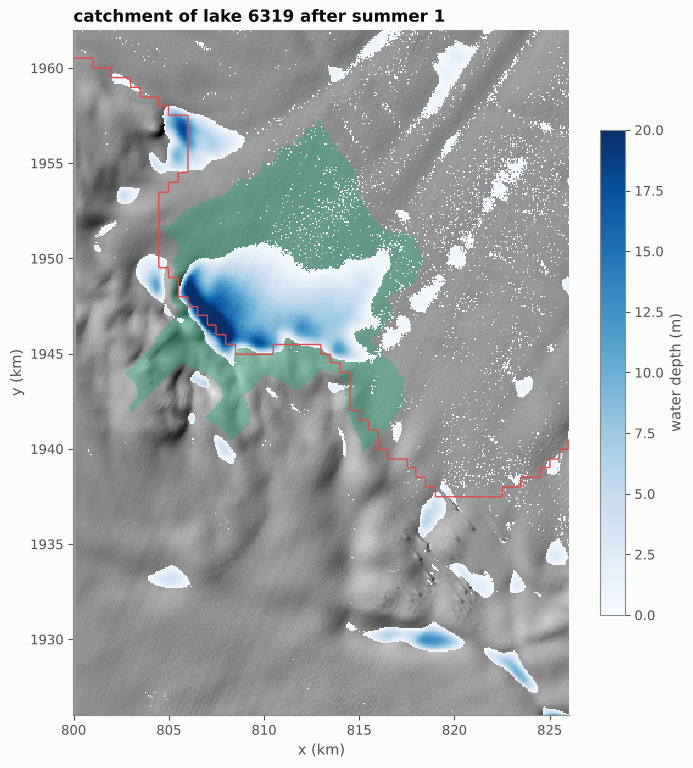

In [2]:
def outlets(labels, lakes, vmin=1e5):
    big = lakes.lake.values[lakes.volume.values >= vmin]
    return labels.where(labels.isin(big), 0)

t0 = time.perf_counter()
basins1 = drainage_basins(dem, outlets(labels1, lakes1))
catchment = basins1 == LAKE
print(f"drainage basins: {time.perf_counter() - t0:.1f} s; lake {LAKE} drains "
      f"{float(catchment.sum()) * area / 1e6:.0f} km² ({100 * float(catchment.mean()):.0f}% of the domain)")

BOX = dict(x=slice(dem.x.values[0], dem.x.values[0] + 26e3), y=slice(1.962e6, 1.926e6))
fig, ax = plt.subplots(figsize=(8, 9))
show_map(ax, hs.sel(**BOX), f"catchment of lake {LAKE} after summer 1", cmap="gray", vmin=0, vmax=1)
show_map(ax, catchment.where(catchment).sel(**BOX), cmap=ListedColormap([ps.ISO]), alpha=0.35)
im = show_map(ax, s1.where(s1 > 0.05).sel(**BOX), cmap="Blues", vmin=0, vmax=20)
plt.colorbar(im, ax=ax, shrink=0.7, label="water depth (m)")
grounding_line(ax, floating.sel(**BOX));

## 2. The lake drains in winter: rebound

This is the same calculation as in the drainage notebook: a 400 m thick plate on a 128 m grid, with grounded ice held fixed, starting from a shelf fully relaxed under the lake. The maps show the uplift at the end of drainage, at the start of summer 2 (day 180) and after a year.

rebound over a year: 43 s


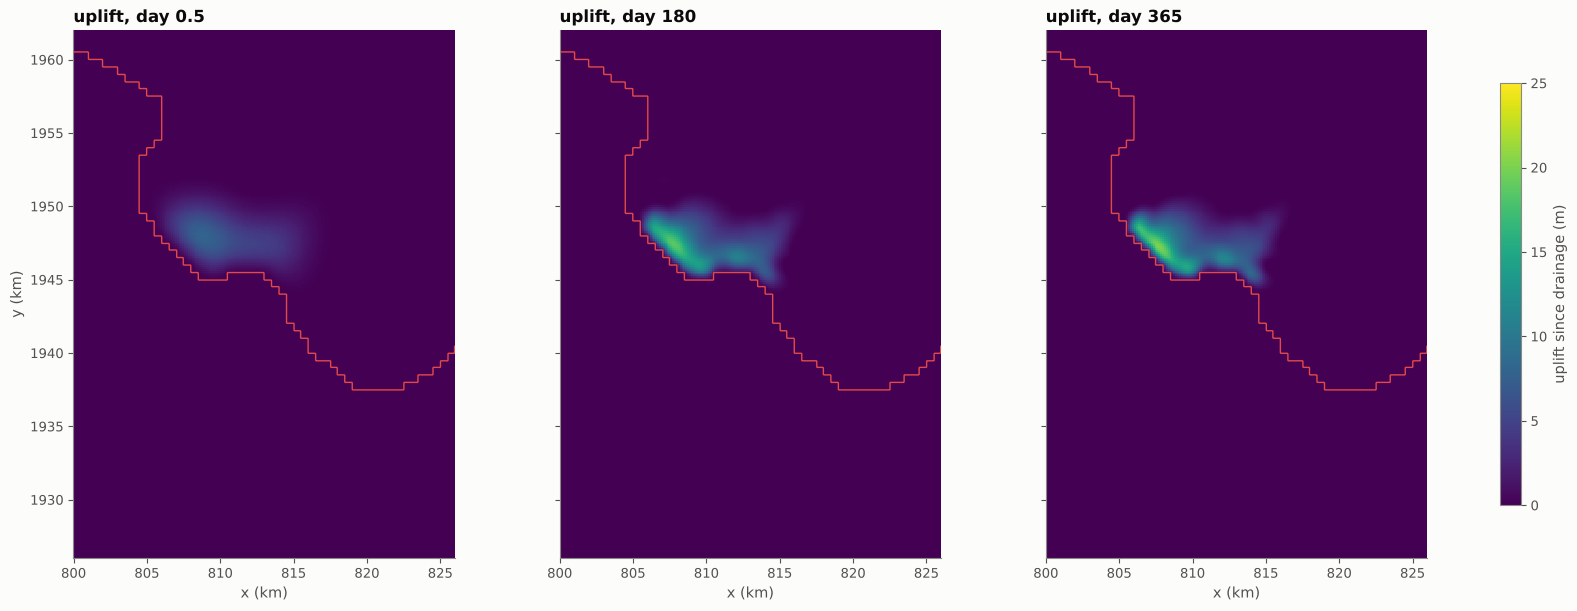

In [3]:
shelf = IceShelf(H=400.0)
plate = ShelfPlate(dem, floating, shelf, coarsen=2)
NEXT = 180                                    # days from drainage to the next melt season
OUT = np.array([0.5, 10, 30, 100, NEXT, 365]) * DAY
t0 = time.perf_counter()
resp = drain_lake(plate, lakeL, OUT, drain_time=0.5 * DAY)
print(f"rebound over a year: {time.perf_counter() - t0:.0f} s")

def rebounded(td):
    # the surface td days after drainage; outlet (ocean) cells stay outlets
    up = plate.to_grid(resp.uplift.sel(time_days=td, method="nearest"))
    return (dem + up).where(dem > 0, dem).rename("surface")

fig, ax = plt.subplots(1, 3, figsize=(16, 6), sharey=True, constrained_layout=True)
for a, td in zip(ax, [0.5, NEXT, 365]):
    im = show_map(a, resp.uplift.sel(time_days=td, method="nearest").sel(**BOX), f"uplift, day {td:g}",
                  cmap="viridis", vmin=0, vmax=25)
    grounding_line(a, floating.sel(**BOX))
for a in ax[1:]:
    a.set_ylabel("")
fig.colorbar(im, ax=ax, shrink=0.8, label="uplift since drainage (m)");

## 3. The old basin shrinks

How much can the old basin hold now? We flood its footprint with 20 m of water, far more than it can take, route it, and measure what stays inside the footprint. The answer does not depend on the 20 m: any amount that overfills the basin gives the same capacity.

In [4]:
def capacity(surface, depth=20.0):
    d = route(surface, xr.where(footprint, depth, 0.0))
    return Mm3(d.where(footprint).sum())

cap0 = capacity(dem)
times_d = OUT / DAY
caps = np.array([capacity(rebounded(td)) for td in times_d])
print(f"basin capacity before drainage: {cap0:.0f} Mm³ (the lake held {V_L:.0f} Mm³)")
for td, c in zip(times_d, caps):
    print(f"  {td:5g} days after drainage: {c:5.0f} Mm³ ({100 * c / cap0:3.0f}%)")

basin capacity before drainage: 366 Mm³ (the lake held 344 Mm³)
    0.5 days after drainage:   224 Mm³ ( 61%)
     10 days after drainage:   177 Mm³ ( 48%)
     30 days after drainage:   149 Mm³ ( 41%)
    100 days after drainage:   124 Mm³ ( 34%)
    180 days after drainage:   114 Mm³ ( 31%)
    365 days after drainage:   102 Mm³ ( 28%)


## 4. Summer 2 on a fixed surface: where does the water go?

First, the simplest version. Summer 2's melt is routed all at once over the surface as it stands at different times after drainage. Each result is compared with routing over the surface without rebound. Water is counted in three places:

* inside the old lake's footprint;
* anywhere else on the shelf;
* lost at the edge of the domain.

In [5]:
def summer2(surface):
    return route(surface, others + MELT)

def budget(w):
    inside = Mm3(w.where(footprint).sum())
    total = Mm3(w.sum())
    released = Mm3((others + MELT).sum())
    return dict(old_basin=inside, elsewhere=total - inside, left_domain=released - total)

rows = {"no rebound": budget(summer2(dem))}
for td in times_d:
    rows[f"{td:g} d after"] = budget(summer2(rebounded(td)))
static = pd.DataFrame(rows).T
static.index.name = "surface"
static.round(0)

,old_basin,elsewhere,left_domain
surface,,,
no rebound,366.0,276.0,1210.0
0.5 d after,224.0,275.0,1353.0
10 d after,177.0,276.0,1400.0
30 d after,149.0,276.0,1427.0
100 d after,124.0,276.0,1452.0
180 d after,114.0,276.0,1463.0
365 d after,102.0,276.0,1475.0


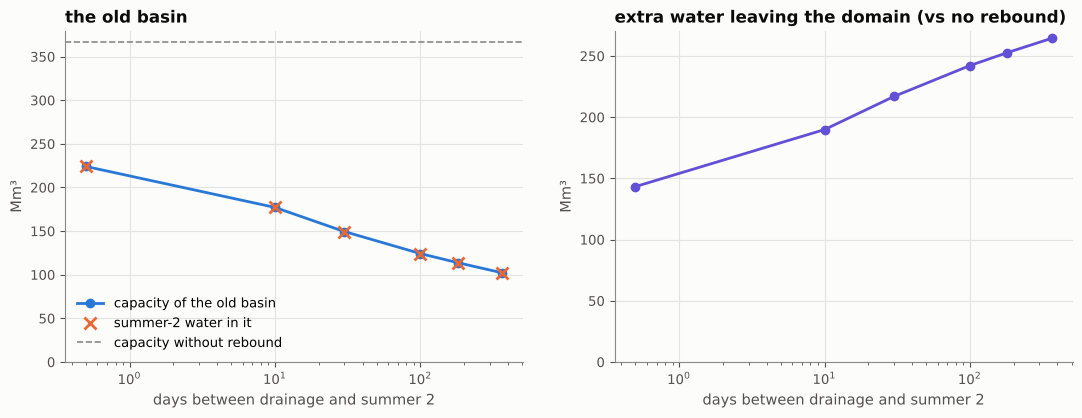

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
ax[0].semilogx(times_d, caps, "o-", color=ps.VISCO, label="capacity of the old basin")
ax[0].semilogx(times_d, static.old_basin.values[1:], "x", color=ps.ELASTIC, ms=9, mew=2, label="summer-2 water in it")
ax[0].axhline(cap0, color=ps.MUTED, ls="--", lw=1.2, label="capacity without rebound")
ax[0].set(xlabel="days between drainage and summer 2", ylabel="Mm³", ylim=(0, None), title="the old basin")
ax[0].legend(loc="lower left")
extra = static.left_domain.values[1:] - static.left_domain.values[0]
ax[1].semilogx(times_d, extra, "o-", color=ps.ACCENT)
ax[1].set(xlabel="days between drainage and summer 2", ylabel="Mm³", ylim=(0, None),
          title="extra water leaving the domain (vs no rebound)");

### The flow paths stay; the basin overflows

Two questions remain: does the water still flow *into* the old basin, and once the basin is full, where does the rest go?

* **Catchment.** We compare the area whose water reaches the old basin first, with and without rebound. The surface used is the one at the start of summer 2 (day 180), and the lakes of the static summer-2 routing serve as outlets.
* **Overflow route.** We call `drainage_basins(..., return_receivers=True)` with only the domain edge as an outlet, which also gives each cell's downstream neighbour. Following those neighbours from the basin floor with `flow_route` climbs to the basin's spill point and then runs downhill. Only the route beyond the old lake's footprint is drawn, because inside a full lake the water surface is flat and the path is arbitrary.

area draining first into the old basin: 205 km² without rebound, 205 km² with rebound (shared: 205 km²)


      no rebound: spills at (817.0, 1951.3) km, 93.6 m; leaves the domain at (814.1, 2000.0) km after 71 km


rebound, day 180: spills at (817.0, 1951.3) km, 93.6 m; leaves the domain at (814.1, 2000.0) km after 68 km


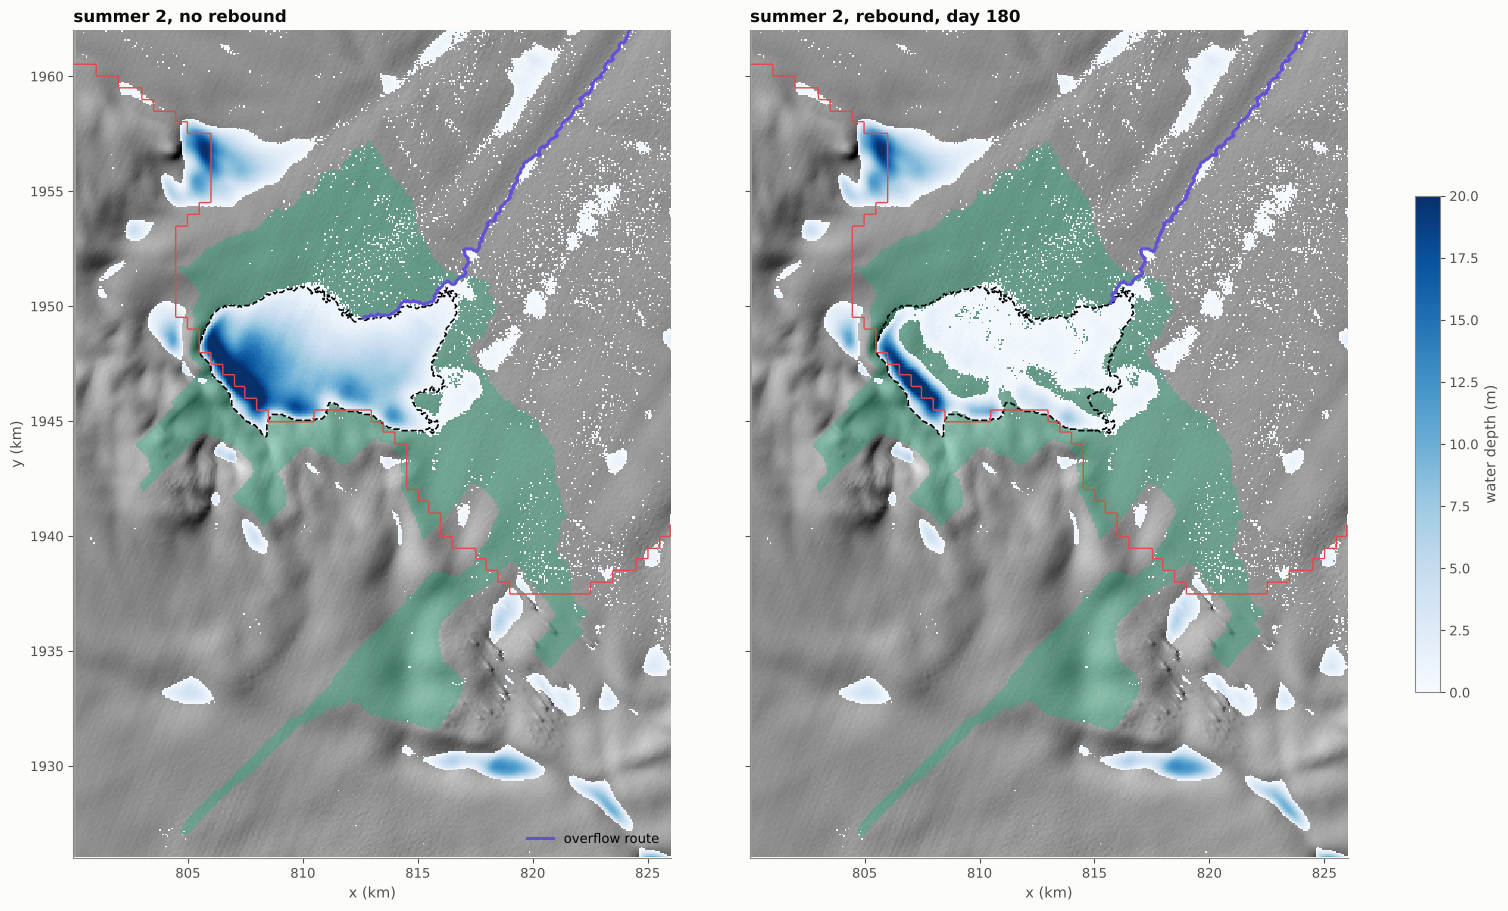

In [7]:
w_no, w_180 = summer2(dem), summer2(rebounded(NEXT))
lab_no, lakes_no = find_lakes(w_no, floating)
lab_180, lakes_180 = find_lakes(w_180, floating)
first_no = drainage_basins(dem, outlets(lab_no, lakes_no)).isin(lake_for(lab_no, footprint))
first_180 = drainage_basins(rebounded(NEXT), outlets(lab_180, lakes_180)).isin(lake_for(lab_180, footprint))
km2 = lambda m: float(m.sum()) * area / 1e6
print(f"area draining first into the old basin: {km2(first_no):.0f} km² without rebound, "
      f"{km2(first_180):.0f} km² with rebound (shared: {km2(first_no & first_180):.0f} km²)")

floor = dem.where(footprint)                          # start the overflow route at the basin floor
iy, ix = np.unravel_index(int(floor.fillna(np.inf).argmin()), floor.shape)
x0, y0 = float(dem.x[ix]), float(dem.y[iy])
routes = {}
for name, surf in [("no rebound", dem), (f"rebound, day {NEXT}", rebounded(NEXT))]:
    _, rec = drainage_basins(surf, xr.zeros_like(labels1), return_receivers=True)
    r = flow_route(rec, x0, y0)
    inside = footprint.sel(x=r.x, y=r.y).values
    r = r.isel(step=slice(int(np.flatnonzero(inside)[-1]), None))
    z_r = surf.sel(x=r.x, y=r.y).values
    k = int(np.argmax(z_r))
    routes[name] = r
    print(f"{name:>16}: spills at ({float(r.x[k]) / 1e3:.1f}, {float(r.y[k]) / 1e3:.1f}) km, {z_r[k]:.1f} m; "
          f"leaves the domain at ({float(r.x[-1]) / 1e3:.1f}, {float(r.y[-1]) / 1e3:.1f}) km after {r.sizes['step'] * 0.064:.0f} km")

fig, ax = plt.subplots(1, 2, figsize=(15, 9), sharey=True, constrained_layout=True)
for a, w_, c_, (name, r) in zip(ax, [w_no, w_180], [first_no, first_180], routes.items()):
    show_map(a, hs.sel(**BOX), f"summer 2, {name}", cmap="gray", vmin=0, vmax=1)
    show_map(a, c_.where(c_).sel(**BOX), cmap=ListedColormap([ps.ISO]), alpha=0.35)
    im = show_map(a, w_.where(w_ > 0.05).sel(**BOX), cmap="Blues", vmin=0, vmax=20)
    a.contour(footprint.sel(**BOX).x / 1e3, footprint.sel(**BOX).y / 1e3, footprint.sel(**BOX).astype(float),
              levels=[0.5], colors="k", linewidths=1.2, linestyles="--")
    a.plot(r.x / 1e3, r.y / 1e3, color=ps.ACCENT, lw=2.2, label="overflow route")
    grounding_line(a, floating.sel(**BOX))
    a.set_xlim(BOX["x"].start / 1e3, BOX["x"].stop / 1e3)
    a.set_ylim(BOX["y"].stop / 1e3, BOX["y"].start / 1e3)
ax[1].set_ylabel("")
ax[0].legend(loc="lower right")
fig.colorbar(im, ax=ax, shrink=0.6, label="water depth (m)");

## 5. Summer 2 with the shelf still moving

In reality the shelf keeps moving through summer 2. It is still rebounding from the drainage, and it sags under any water that runs back into the old basin. So the coupled run starts the plate from its state 180 days after drainage (`ShelfPlate.restore`) and routes and flexes together, day by day.

The plate is loaded by `water − reference_water`, the water the DEM does not already account for. Here the DEM is the surface relaxed under all of summer 1's lakes, so `reference_water` is summer 1's water. The drained lake then appears as a negative load and new water as a positive one.

The three runs are:

| run | surface during summer 2 |
|---|---|
| `no rebound` | the DEM: ordinary fill-spill-merge, which ignores flexure |
| `rebound, fixed` | the rebounded surface at day 180, held fixed |
| `coupled` | rebounding from the drainage *and* sagging under new water, updated daily |

In [8]:
SEASON, AFTER = 60, 30
days = np.arange(SEASON + AFTER + 1)
rate = np.where(days[:-1] < SEASON, np.sin(np.pi * (days[:-1] + 0.5) / SEASON) ** 2, 0.0)
melt_per_day = MELT * rate / rate.sum()
melt = lambda i: xr.full_like(dem, melt_per_day[i])
t2 = (NEXT + days) * DAY
STORE = [0, 20, 40, 60, 90]
track = {"old basin": footprint}

runs = {}
t0 = time.perf_counter()
runs["no rebound"] = route_with_flexure(dem, melt, t2, water0=others, store=STORE, track=track)
runs["rebound, fixed"] = route_with_flexure(rebounded(NEXT), melt, t2, water0=others, store=STORE, track=track)
snap = resp.isel(time=int(np.argmin(np.abs(resp.time_days.values - NEXT))))
plate.restore(snap)
runs["coupled"] = route_with_flexure(dem, melt, t2, plate=plate, water0=others, reference_water=s1,
                                     store=STORE, track=track)
print(f"three summers: {time.perf_counter() - t0:.0f} s")

three summers: 171 s


,old_basin,elsewhere,left_domain
no rebound,366.0,276.0,1210.0
"rebound, fixed",114.0,276.0,1463.0
coupled,307.0,304.0,1242.0


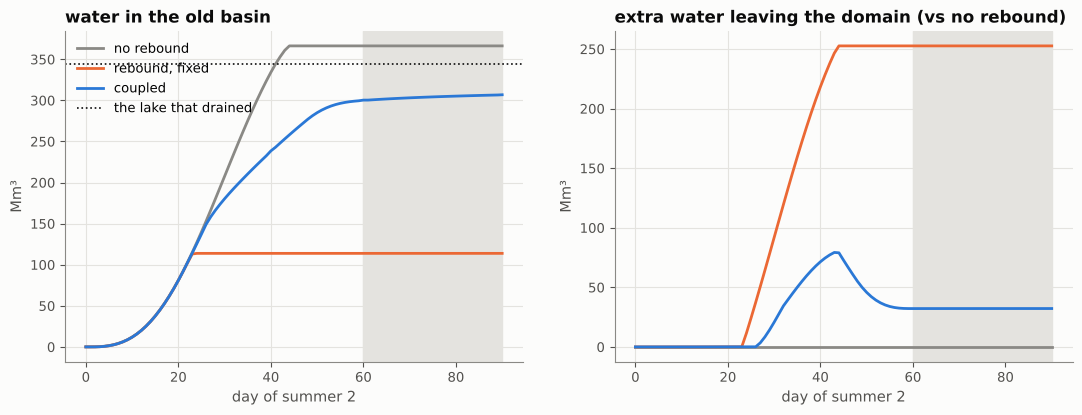

In [9]:
cols = {"no rebound": ps.MUTED, "rebound, fixed": ps.ELASTIC, "coupled": ps.VISCO}
fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
for name, r in runs.items():
    d_ = r.step_time_days - NEXT
    ax[0].plot(d_, r.tracked_volume.sel(region="old basin") / 1e6, color=cols[name], label=name)
    ax[1].plot(d_, (r.water_lost - runs["no rebound"].water_lost) / 1e6, color=cols[name], label=name)
ax[0].axhline(V_L, color=ps.INK, ls=":", lw=1.2, label="the lake that drained")
ax[0].set(xlabel="day of summer 2", ylabel="Mm³", title="water in the old basin")
ax[1].set(xlabel="day of summer 2", ylabel="Mm³", title="extra water leaving the domain (vs no rebound)")
for a in ax:
    a.axvspan(SEASON, days[-1], color=ps.GRID, zorder=0)
ax[0].legend(loc="upper left")

end = {name: dict(old_basin=float(r.tracked_volume[-1, 0]) / 1e6,
                  elsewhere=(float(r.water_stored[-1]) - float(r.tracked_volume[-1, 0])) / 1e6,
                  left_domain=float(r.water_lost[-1]) / 1e6) for name, r in runs.items()}
pd.DataFrame(end).T.round(0)

### Maps and a profile at the end of summer 2

The profile is a west–east line through the old lake. It shows four surfaces:

* the pre-drainage surface (the DEM), with the summer-1 lake;
* the surface at the start of summer 2;
* the end-of-summer surfaces and water for the coupled and no-rebound runs.

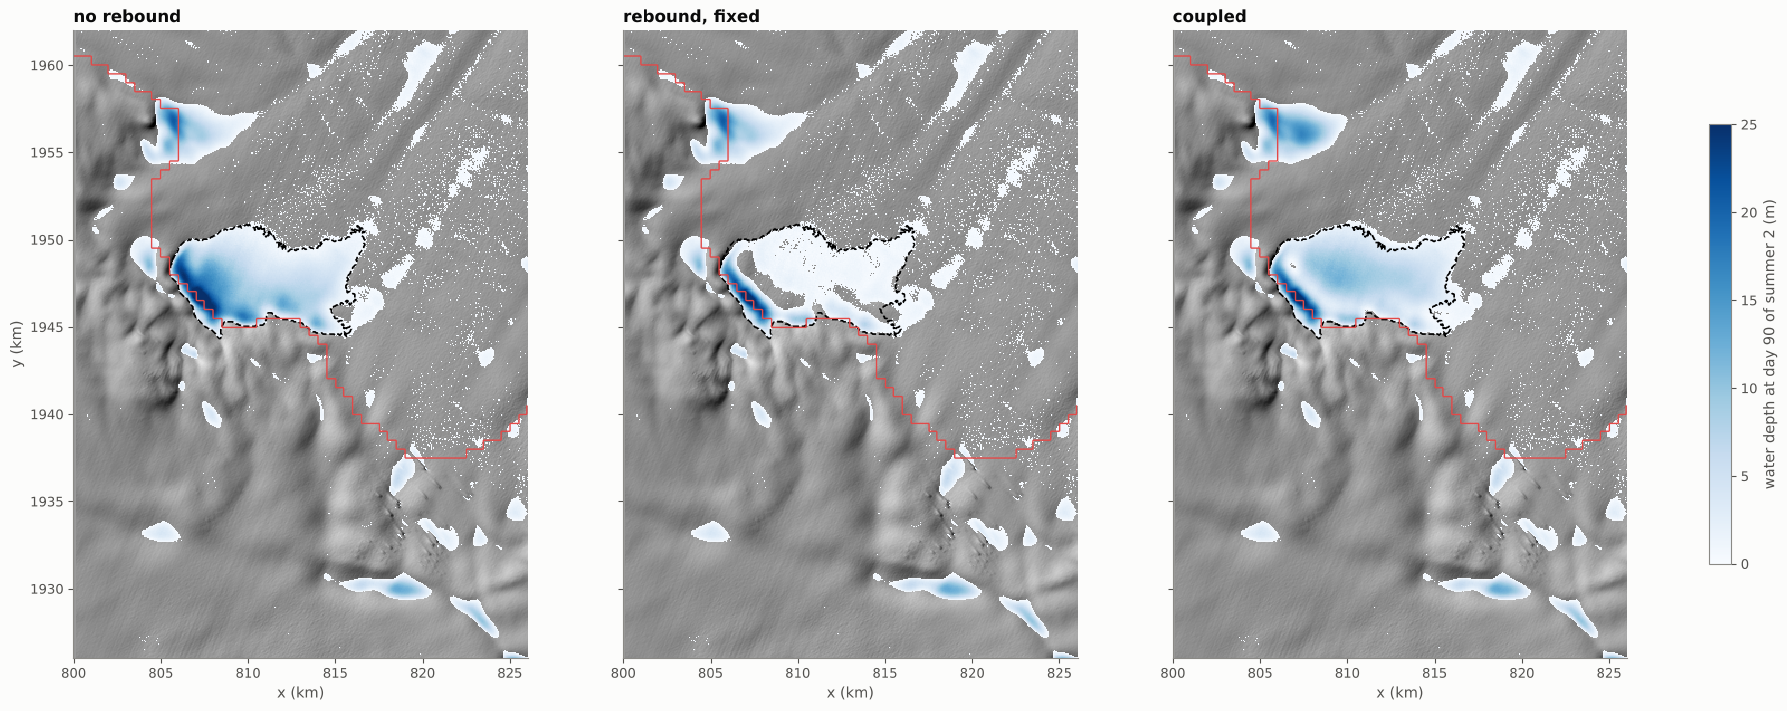

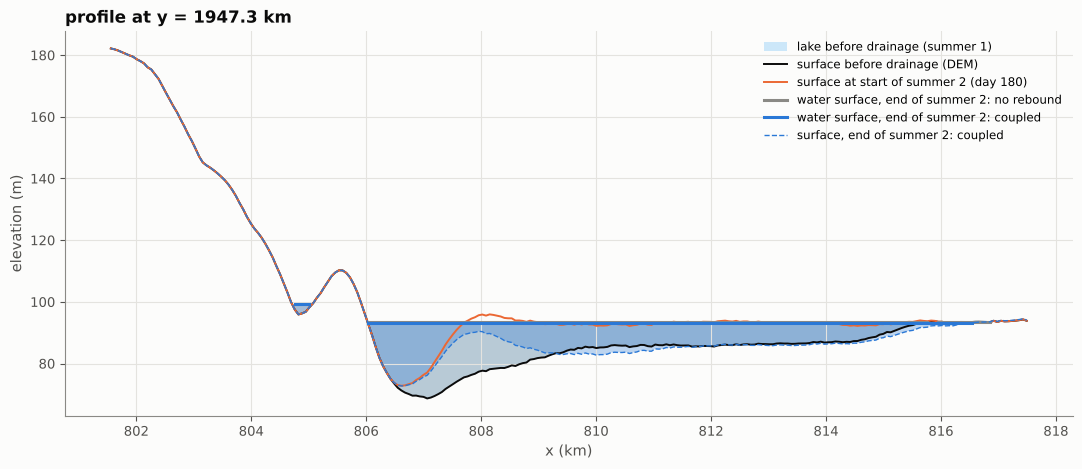

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(18, 7), sharey=True, constrained_layout=True)
for a, name in zip(ax, runs):
    e = runs[name].isel(time=-1)
    show_map(a, hs.sel(**BOX), name, cmap="gray", vmin=0, vmax=1)
    im = show_map(a, e.water_depth.where(e.water_depth > 0.05).sel(**BOX), cmap="Blues", vmin=0, vmax=25)
    a.contour(footprint.sel(**BOX).x / 1e3, footprint.sel(**BOX).y / 1e3, footprint.sel(**BOX).astype(float),
              levels=[0.5], colors="k", linewidths=1.2, linestyles="--")
    grounding_line(a, floating.sel(**BOX))
for a in ax[1:]:
    a.set_ylabel("")
fig.colorbar(im, ax=ax, shrink=0.7, label=f"water depth at day {days[-1]} of summer 2 (m)")

yc = float(lakes1.y_centre.sel(lake=LAKE))
xc = float(lakes1.x_centre.sel(lake=LAKE))
XS = slice(xc - 8e3, xc + 8e3)
row = lambda da: da.sel(y=yc, method="nearest").sel(x=XS)
fig, ax = plt.subplots(figsize=(13, 5))
x_ = row(dem).x / 1e3
ax.fill_between(x_, row(dem), row(dem + lakeL), where=row(lakeL) > 0, color=ps.WATER, alpha=0.25, lw=0,
                label="lake before drainage (summer 1)")
ax.plot(x_, row(dem), color=ps.INK, lw=1.4, label="surface before drainage (DEM)")
ax.plot(x_, row(rebounded(NEXT)), color=ps.ELASTIC, lw=1.4, label=f"surface at start of summer 2 (day {NEXT})")
for name, c in [("no rebound", ps.MUTED), ("coupled", ps.VISCO)]:
    e = runs[name].isel(time=-1)
    s_, d_ = row(e.surface), row(e.water_depth)
    ax.fill_between(x_, s_, s_ + d_, where=d_ > 0.05, color=c, alpha=0.3, lw=0)
    ax.plot(x_, s_ + d_.where(d_ > 0.05), color=c, lw=2.2, label=f"water surface, end of summer 2: {name}")
    if name == "coupled":
        ax.plot(x_, s_, color=c, lw=1.0, ls="--", label="surface, end of summer 2: coupled")
ax.set(xlabel="x (km)", ylabel="elevation (m)", title=f"profile at y = {yc / 1e3:.1f} km")
ax.legend(fontsize=8.5, loc="upper right");

## 6. Record

The drainage response (cropped to the area around the lake) and the three summer-2 runs are written to `outputs/` as compressed NetCDF.

In [11]:
def save(ds, name):
    enc = {v: {"zlib": True, "complevel": 4, **({"dtype": "float32"} if ds[v].dtype.kind == "f" else {})}
           for v in ds.data_vars}
    path = os.path.join(OUT_DIR, name)
    ds.to_netcdf(path, encoding=enc)
    print(f"{path}: {os.path.getsize(path) / 1e6:.1f} MB")

meta = dict(lake_label=int(LAKE), lake_volume_m3=V_L * 1e6, melt_m=MELT, next_summer_day=NEXT, dem_file=DEM_FILE)
save(resp.sel(**BOX).assign_attrs(meta), f"reorganisation_lake_{LAKE}_drainage.nc")
for name, r in runs.items():
    save(r.assign_attrs(meta, run=name), f"reorganisation_summer2_{name.replace(', ', '_').replace(' ', '_')}.nc")

outputs/reorganisation_lake_6319_drainage.nc: 4.4 MB


outputs/reorganisation_summer2_no_rebound.nc: 10.5 MB


outputs/reorganisation_summer2_rebound_fixed.nc: 10.7 MB


outputs/reorganisation_summer2_coupled.nc: 15.4 MB


## Summary

**Back into the basin, or redirected?** Into the basin first. Once the much smaller basin is full, the rest is redirected along the old basin's overflow route. How much the basin can hold depends on whether the shelf is still moving.

* **Rebound shrinks the basin.** Draining the 344 Mm³ grounding-line lake lifts the old lake floor by up to about 20 m within a year. The basin's capacity falls from 366 Mm³ to 224 Mm³ (61%) by the end of drainage, 114 Mm³ (31%) by the next summer and 102 Mm³ (28%) after a year. What remains is mostly a trough against the grounding line, where grounded ice pins the shelf so it cannot rise.
* **Flow paths barely change.** The same 205 km² drains first into the old basin with and without rebound. The basin's spill point (93.6 m, at its eastern end) and its overflow route are also unchanged; that route runs 70 km north across the shelf to the domain's northern edge, which this DEM marks as ocean.
* **On a fixed rebounded surface** the next summer fills the remnant (114 Mm³) by about day 23. After that, 253 Mm³ more water overflows and leaves the shelf than if there had been no rebound.
* **But the shelf keeps moving.** As water runs back in, its weight pushes the basin floor down again. In the coupled run the basin holds 307 Mm³ by the end of summer 2: 84% of its pre-drainage capacity and 89% of the drained lake. Only 32 Mm³ extra overflows. The refilling is gradual: the basin is still sinking and taking water after the no-rebound basin has filled (day 44). Other lakes hold a little more too (304 against 276 Mm³), as in the coupled-routing notebook.
* **Relation to Warner et al. (2021).** The model reproduces the parts of their story that come from flexure: tens of metres of rebound of the unloaded shelf, and the next summer's meltwater returning to the old basin to refill it. It cannot make the doline's collapsed centre, which needs fracture, or the incised channel. Its numbers are for a different shelf, a lake half the size (0.34 against 0.75 km³) and an assumed ice thickness of 400 m.

**Caveats:**

* The DEM is taken to be the surface relaxed under summer 1's lakes, and the other lakes keep their load through the winter.
* Thickness and rheology are uniform, and grounded ice is fixed at the 500 m mask.
* Melt is uniform, and routing is instantaneous, with no slush, firn storage or channel incision.
* Water that reaches the edge of the domain leaves it.